# Evaluation baseline

Avant d'optimiser le modèle, il est nécessaire d'établir une **baseline**, c'est-à-dire une référence permettant de mesurer ses performances initiales et d'identifier ses limites.

Ce notebook restitue la démarche exploratoire initiale :

- Comprendre le comportement du modèle sur nos données.
- Identifier et justifier les métriques d'évaluation pertinentes.
- Analyser les erreurs et les difficultés de classification. 
- Formuler des hypothèses et définir les expérimentations complémentaires.

## Modèle de référence

Le modèle sélectionné est un classifieur anatomique de radiographies, préentraîné sur ImageNet puis spécialisé sur des images radiologiques.

**Source :** [emon5122/xray-bodypart-classifier — Hugging Face](https://huggingface.co/emon5122/xray-bodypart-classifier)

| Caractéristique | Configuration initiale |
|---|---|
| Architecture | ConvNeXt-Tiny |
| Framework | PyTorch / timm |
| Poids | `best.pt` — poids fournis par l'auteur |
| Précision numérique | FP32 |
| Nombre de classes | 33 |
| Dimensions d'entrée | 224 × 224 × 3 |
| Prétraitement | Resize proportionnel + Center Crop |
| Normalisation | ImageNet |
| Fonction de sortie | Softmax appliquée aux logits |
| Matériel | CPU |
| Réentraînement | Aucun |

Cette configuration conserve les poids et le protocole de prétraitement recommandés par l'auteur. Elle constitue notre point de référence avant toute optimisation.

### Performances annoncées

Le modèle a été entraîné sur environ 37 000 images radiologiques. L'auteur rapporte les performances suivantes sur un ensemble de validation de 7 354 images couvrant les 33 classes.

| Métrique | Résultat annoncé |
|---|---:|
| Accuracy Top-1 | 70,4 % |
| Accuracy Top-5 | 94,0 % |

L'auteur identifie notamment des difficultés liées au chevauchement de certaines classes anatomiques et à la reconnaissance des classes peu représentées.

Le modèle est destiné à l'assistance à la classification anatomique et non au diagnostic médical.

## Dataset d'évaluation

Les données d'entraînement du modèle n'étant pas accessibles publiquement, un jeu de données d'évaluation spécifique a été constitué à partir du dataset IRMA.

**Source :** [IRMA X-ray Dataset — Kaggle](https://www.kaggle.com/datasets/raddar/irma-xray-dataset)

| Caractéristique | Configuration |
|---|---|
| Nom du benchmark | `benchmark_v1` |
| Nombre d'images | 200 |
| Nombre de classes évaluées | 10 |
| Distribution | 20 images par classe |
| Partition source | Development |
| Sélection | Échantillonnage aléatoire |
| Seed | 42 |
| Format | PNG |

Le choix d'un dataset équilibré permet d'étudier les performances par région anatomique sans privilégier les classes majoritaires.

Les performances obtenues ne sont pas directement comparables à celles annoncées par l'auteur, les datasets et la distribution des classes étant différents.

## Chargement des données

Les exports de la première évaluation sont chargés avec les annotations du benchmark. Les contrôles vérifient la correspondance des images, des labels et des métriques enregistrées.

In [9]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from torchvision import transforms
from sklearn.metrics import precision_recall_fscore_support

RACINE = Path.cwd()
if RACINE.name == "notebooks":
    RACINE = RACINE.parent
DATASET = RACINE / "datasets" / "benchmark_v1"
RESULTATS = RACINE / "evaluation" / "resultats"
BASELINE = RESULTATS / "pytorch_fp32_benchmark_v1_center_crop_20261120_120305_271278"

config = json.loads((BASELINE / "configuration.json").read_text(encoding="utf-8"))
metrics = json.loads((BASELINE / "metrics.json").read_text(encoding="utf-8"))
pred = pd.read_csv(BASELINE / "predictions.csv")
labels = pd.read_csv(DATASET / "labels.csv")
assert not labels.filename.duplicated().any() and not pred.filename.duplicated().any()
controle = labels.merge(pred, on="filename", how="outer", validate="one_to_one", indicator=True)
assert controle._merge.eq("both").all() and controle.label.eq(controle.label_reel).all()
assert config["parametres"]["pretraitement"] == "center_crop"
classes = sorted(labels.label.unique())
pred["top5"] = pred.top5_predictions.map(lambda s: [p["classe"] for p in json.loads(s)])
pred["correct"] = pred.label_reel.eq(pred.label_predit)
pred["dans_top5"] = [r in p for r, p in zip(pred.label_reel, pred.top5)]
assert np.isclose(pred.correct.mean(), metrics["accuracy_top1"])
assert np.isclose(pred.dans_top5.mean(), metrics["accuracy_top5"])
print(f"Baseline : {BASELINE.name} | {len(pred)} images | {len(classes)} classes évaluées")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Baseline : pytorch_fp32_benchmark_v1_center_crop_20261120_120305_271278 | 200 images | 10 classes évaluées


## Observation du dataset

Avant d'interpréter les scores, il faut comprendre les données : l'équilibre des classes, la diversité des dimensions et le contenu anatomique des images. Une image par classe est affichée pour illustrer la tâche.

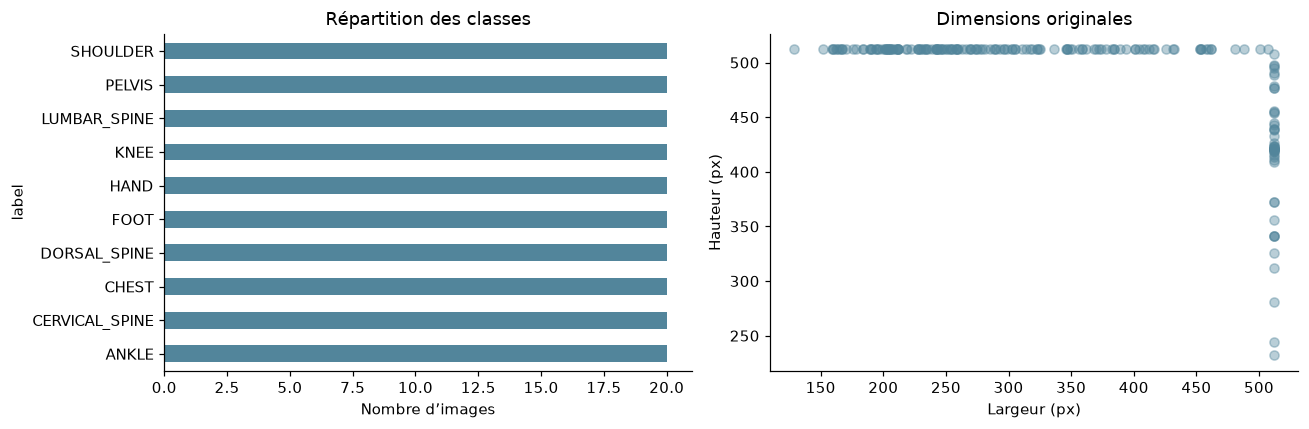

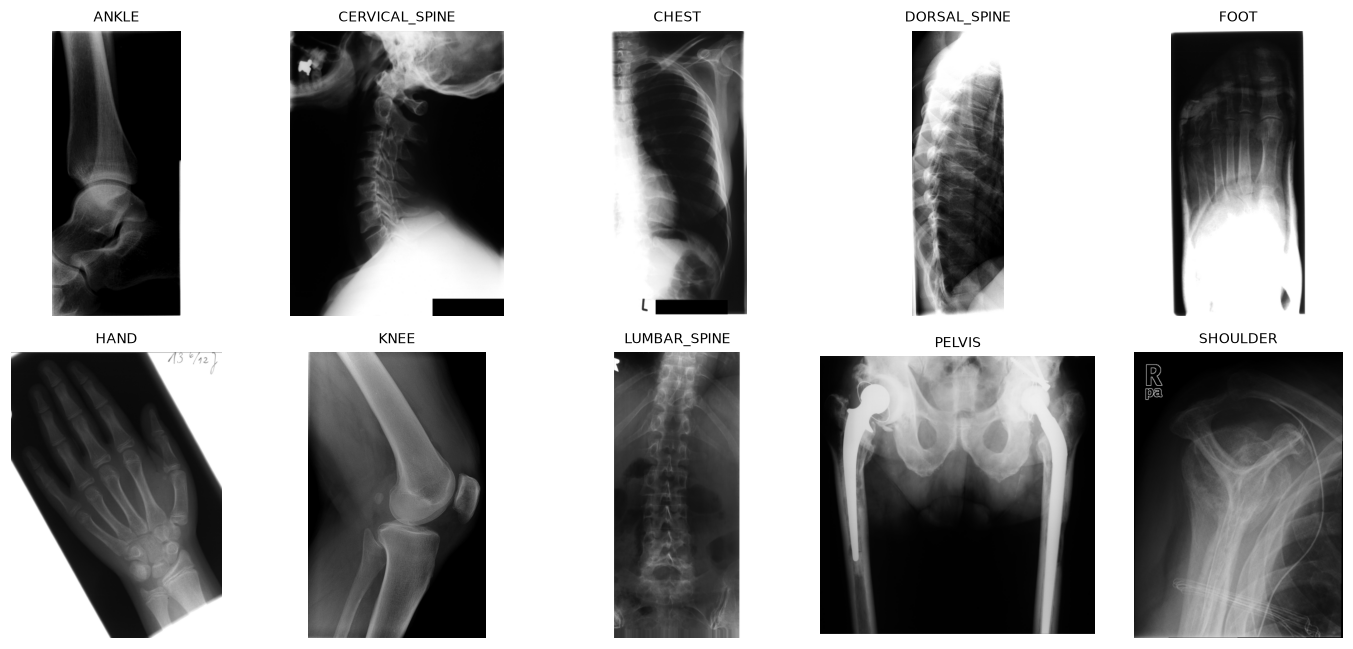

In [10]:
def lire_image(nom):
    with Image.open(DATASET / "images" / nom) as im:
        return im.convert("RGB")

dimensions = pd.DataFrame([lire_image(n).size for n in labels.filename], columns=["largeur", "hauteur"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
labels.label.value_counts().sort_index().plot.barh(ax=ax[0], color="#52859b")
ax[0].set(title="Répartition des classes", xlabel="Nombre d’images")
ax[1].scatter(dimensions.largeur, dimensions.hauteur, alpha=.4, color="#52859b")
ax[1].set(title="Dimensions originales", xlabel="Largeur (px)", ylabel="Hauteur (px)")
plt.tight_layout()
plt.show()

exemples = labels.groupby("label", group_keys=False).sample(n=1, random_state=42)
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, row in zip(axes.flat, exemples.itertuples()):
    ax.imshow(lire_image(row.filename)); ax.set_title(row.label, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

**Observation :** les dix classes sont équilibrées, mais les dimensions et les proportions des images varient. Une annotation unique n'implique pas que seule cette région soit visible. Ces caractéristiques seront utiles pour interpréter les erreurs et examiner le prétraitement.

## Premiers résultats

Une première lecture des indicateurs classiques permet de situer le niveau de performance. Le Top-1 mesure la proportion de premières prédictions correctes ; le Top-5 élargit cette lecture aux cinq propositions. La précision, le rappel et le F1 macro donnent une vision complémentaire des dix classes évaluées. Leur pertinence pour le protocole final sera discutée après l'exploration.

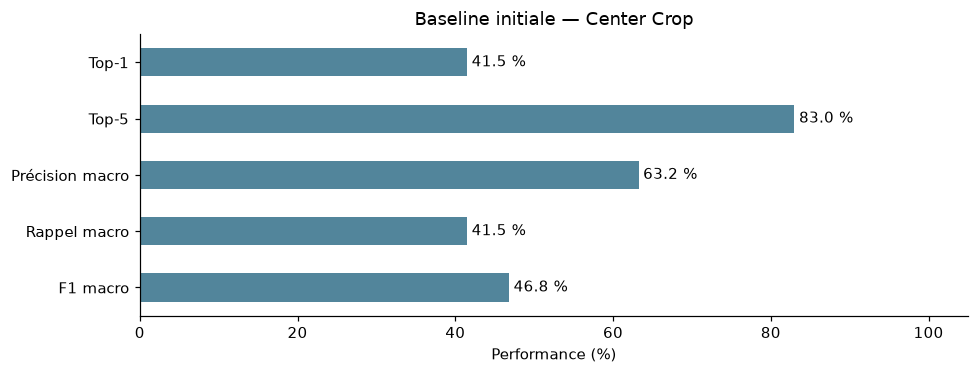

In [11]:
noms = {"accuracy_top1":"Top-1", "accuracy_top5":"Top-5", "precision_macro":"Précision macro", "rappel_macro":"Rappel macro", "f1_macro":"F1 macro"}
bilan = pd.Series({v: metrics[k] for k,v in noms.items()})
ax = (100*bilan).plot.barh(figsize=(9, 3.5), color="#52859b")
ax.invert_yaxis(); ax.set(xlim=(0, 105), xlabel="Performance (%)", title="Baseline initiale — Center Crop")
ax.bar_label(ax.containers[0], fmt="%.1f %%", padding=3)
plt.tight_layout(); plt.show()

**Observation :** l'Accuracy Top-1 atteint 41,5 %, contre 83 % pour le Top-5. Cela signifie que, si le modèle ne sélectionne la bonne classe en première position que dans moins de la moitié des cas, il parvient néanmoins à la proposer parmi ses cinq premières prédictions dans 83 % des cas.

Cet écart important suggère que le modèle dispose d'une certaine capacité à reconnaître la région anatomique recherchée, mais rencontre des difficultés à sélectionner la catégorie exacte.

Les performances restent inférieures à celles annoncées par l'auteur du modèle (70,4 % en Top-1 et 94 % en Top-5). 

## Identifier les classes problématiques

Les résultats globaux peuvent masquer des écarts importants entre régions. La précision mesure la part de prédictions correctes pour une classe, le rappel la part des images de cette classe reconnues, et le F1 combine les deux. Le graphique permet de localiser les difficultés avant d'étudier les confusions.

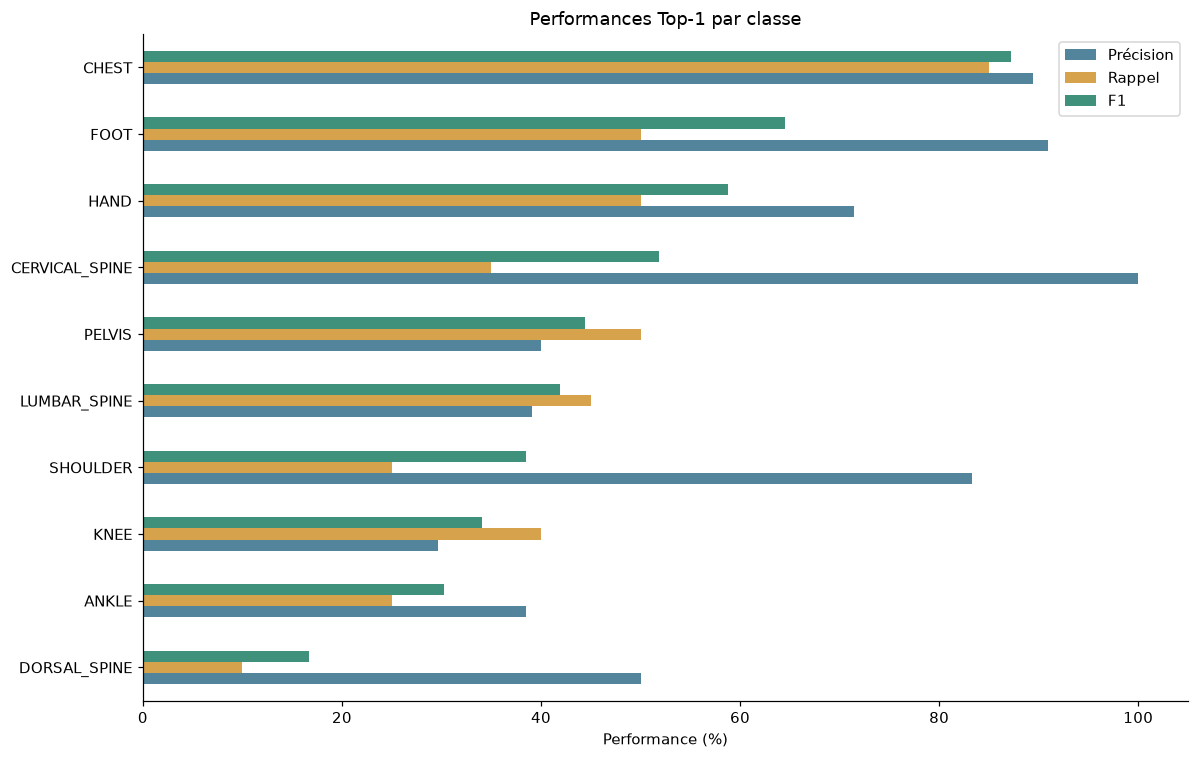

In [24]:
p, r, f, support = precision_recall_fscore_support(pred.label_reel, pred.label_predit, labels=classes, zero_division=0)
par_classe = pd.DataFrame({"Précision": p, "Rappel": r, "F1": f}, index=classes).sort_values("F1")
ax = (100*par_classe).plot.barh(figsize=(11, 7), color=["#52859b", "#d6a24c", "#40917b"])
ax.set(xlim=(0,105), xlabel="Performance (%)", title="Performances Top-1 par classe")
plt.tight_layout(); plt.show()

In [25]:
# Nombre d'images et de classifications correctes par classe
par_classe["Nb images"] = pd.Series(support, index=classes)

par_classe["Nb correctes"] = (
    par_classe["Rappel"] * par_classe["Nb images"]
).round().astype(int)

display(
    par_classe.style.format({
        "Précision": "{:.1%}",
        "Rappel": "{:.1%}",
        "F1": "{:.1%}"
    })
)

,Précision,Rappel,F1,Nb images,Nb correctes
DORSAL_SPINE,50.0%,10.0%,16.7%,20,2
ANKLE,38.5%,25.0%,30.3%,20,5
KNEE,29.6%,40.0%,34.0%,20,8
SHOULDER,83.3%,25.0%,38.5%,20,5
LUMBAR_SPINE,39.1%,45.0%,41.9%,20,9
PELVIS,40.0%,50.0%,44.4%,20,10
CERVICAL_SPINE,100.0%,35.0%,51.9%,20,7
HAND,71.4%,50.0%,58.8%,20,10
FOOT,90.9%,50.0%,64.5%,20,10
CHEST,89.5%,85.0%,87.2%,20,17


**Observation :** les performances du modèle varient fortement selon les régions anatomiques. Le thorax est relativement bien reconnu (17 images sur 20), tandis que le rachis dorsal présente des difficultés importantes (2 images sur 20).

Le rachis cervical présente également un résultat intéressant : une précision de 100 %, mais un rappel de seulement 35 %. Cela signifie que lorsque le modèle prédit cette région, il ne se trompe pas sur notre benchmark. Cependant, 13 des 20 radiographies cervicales sont classées dans une autre catégorie.

Les difficultés observées sur les différentes régions du rachis (cervical, dorsal et lombaire) soulèvent la question de la proximité anatomique des classes. Ces régions partagent des structures osseuses et des caractéristiques visuelles similaires, ce qui pourrait compliquer leur différenciation.

À l'inverse, le thorax présente une structure anatomique globale plus caractéristique, ce qui pourrait faciliter son identification.

**Hypothèse :** certaines erreurs pourraient être liées à la granularité des classes plutôt qu'à une incapacité du modèle à reconnaître la région anatomique générale. L'analyse de la matrice de confusion permettra de vérifier si les erreurs concernent effectivement des régions anatomiquement proches.

## Localiser les confusions

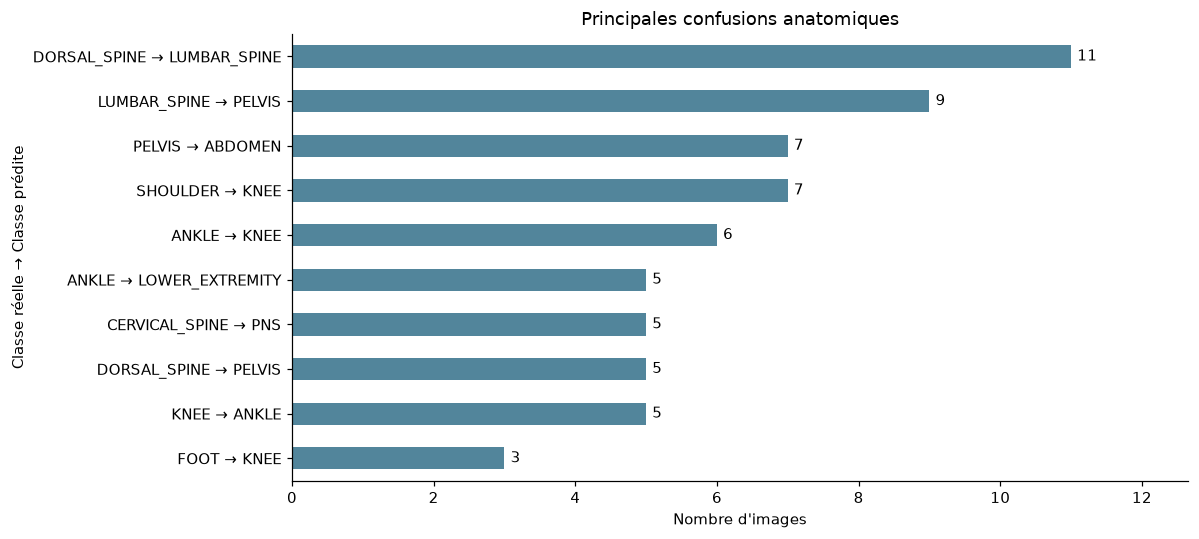

In [26]:
# Identification des principales erreurs de classification
confusions = (
    pred.loc[~pred.correct]
    .groupby(["label_reel", "label_predit"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .reset_index(name="Nombre")
)

confusions["Confusion"] = (
    confusions["label_reel"]
    + " → "
    + confusions["label_predit"]
)

ax = confusions.plot.barh(
    x="Confusion",
    y="Nombre",
    figsize=(11, 5),
    color="#52859b",
    legend=False
)

ax.invert_yaxis()
ax.bar_label(ax.containers[0], padding=4)

ax.set(
    xlabel="Nombre d'images",
    ylabel="Classe réelle → Classe prédite",
    title="Principales confusions anatomiques"
)

ax.set_xlim(0, confusions["Nombre"].max() * 1.15)

plt.tight_layout()
plt.show()

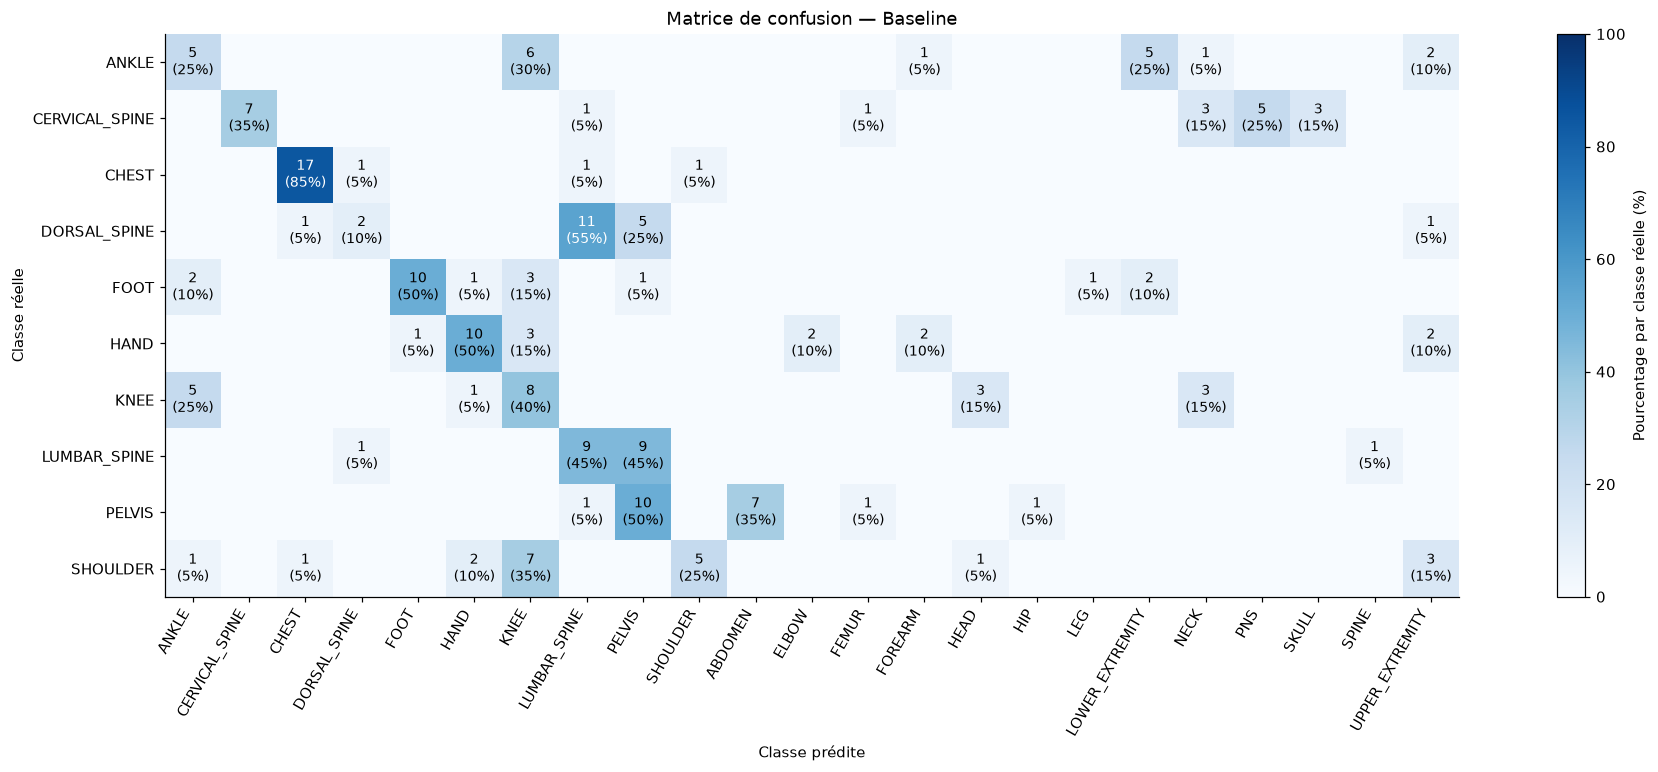

In [29]:
# Construction de la matrice de confusion
colonnes = classes + sorted(set(pred.label_predit) - set(classes))

cm = pd.crosstab(
    pred.label_reel,
    pred.label_predit
).reindex(index=classes, columns=colonnes, fill_value=0)

# Calcul des pourcentages par classe réelle
cm_pct = cm.div(cm.sum(axis=1), axis=0) * 100

# Création du graphique
fig, ax = plt.subplots(
    figsize=(max(14, len(colonnes) * 0.85), 7)
)

im = ax.imshow(cm_pct.values, cmap="Blues", vmin=0, vmax=100)

# Libellés des axes
ax.set_xticks(range(len(colonnes)), colonnes, rotation=60, ha="right")
ax.set_yticks(range(len(classes)), classes)

# Annotation des cellules : effectif et pourcentage
for i, j in np.argwhere(cm.values > 0):

    annotation = (
        f"{cm.iat[i, j]}\n"
        f"({cm_pct.iat[i, j]:.0f}%)"
    )

    ax.text(
        j, i, annotation,
        ha="center",
        va="center",
        color="white" if cm_pct.iat[i, j] > 50 else "black",
        fontsize=9
    )

# Titres et légende
ax.set(
    xlabel="Classe prédite",
    ylabel="Classe réelle",
    title="Matrice de confusion — Baseline"
)

fig.colorbar(im, ax=ax, label="Pourcentage par classe réelle (%)")

plt.tight_layout()
plt.show()

**Observation** : 
L'analyse des confusions fait apparaître deux types d'erreurs.

**Confusions entre régions anatomiquement proches :**

- 55 % des radiographies du rachis dorsal sont classées en rachis lombaire.
- 45 % des radiographies du rachis lombaire sont classées en bassin.
- 35 % des radiographies du bassin sont classées en abdomen.

Ces résultats renforcent l'hypothèse d'une difficulté à différencier certaines régions anatomiques voisines ou partageant des structures visibles sur une même radiographie.

**Confusions entre régions anatomiquement éloignées :**

- 35 % des radiographies de l'épaule sont classées en genou.

Ces erreurs ne peuvent pas être expliquées uniquement par la proximité anatomique. D'autres facteurs pourraient intervenir, comme la similarité visuelle des articulations, le cadrage ou le prétraitement des images.

Les exemples suivants ciblent les confusions fréquentes du rachis et les erreurs les plus confiantes. L'annotation, la prédiction et la présence de la bonne classe dans le Top-5 sont affichées pour examiner chaque cas. Cet échantillon ciblé illustre des erreurs ; il ne représente pas leur fréquence globale.

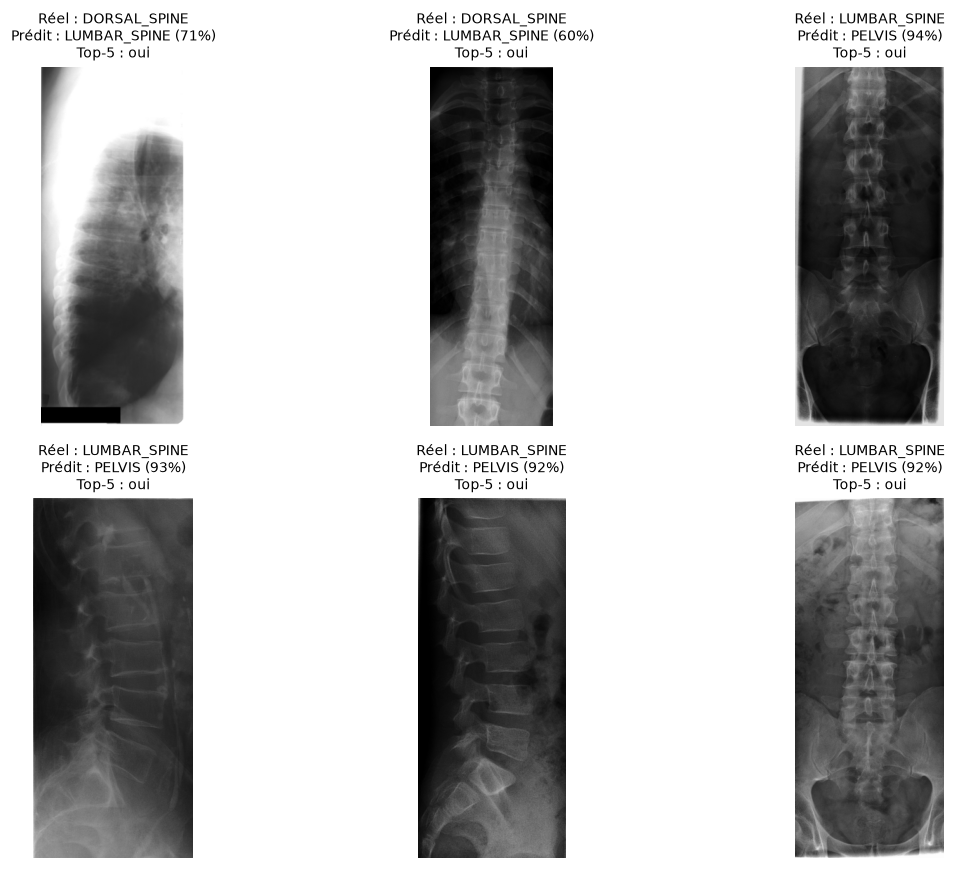

In [15]:
# Exemples reproductibles : deux confusions fréquentes et erreurs les plus confiantes.
erreurs = pred.loc[~pred.correct].sort_values("score_top1", ascending=False)
choix = pd.concat([
    erreurs.loc[erreurs.label_reel.eq("DORSAL_SPINE") & erreurs.label_predit.eq("LUMBAR_SPINE")].head(2),
    erreurs.loc[erreurs.label_reel.eq("LUMBAR_SPINE") & erreurs.label_predit.eq("PELVIS")].head(2),
    erreurs.head(6)
]).drop_duplicates("filename").head(6)
fig, axes = plt.subplots(2,3,figsize=(12,8))
for ax in axes.flat: ax.axis("off")
for ax,row in zip(axes.flat,choix.itertuples()):
    ax.imshow(lire_image(row.filename))
    ax.set_title(f"Réel : {row.label_reel}\nPrédit : {row.label_predit} ({row.score_top1:.0%})\nTop-5 : {'oui' if row.dans_top5 else 'non'}",fontsize=9)
plt.tight_layout(); plt.show()

**Interprétation :** une radiographie lombaire peut montrer une partie du bassin, et les régions du rachis peuvent partager des repères visuels. La présence de plusieurs régions est une hypothèse explicative à examiner sur les images affichées, pas une validation clinique des prédictions. Il devient intéressant de vérifier si la bonne région figure néanmoins parmi les autres propositions.

## Approfondir l'apport du Top-5

Les premiers résultats montrent un écart important entre l'Accuracy Top-1 (41,5 %) et l'Accuracy Top-5 (83 %).
Afin de mieux comprendre cet écart, l'analyse est étendue aux rangs intermédiaires : Top-2, Top-3 et Top-4.

L'objectif est de déterminer dans quelle proportion la classe attendue apparaît lorsque le nombre de propositions augmente.
Cette analyse permettra notamment de déterminer si un nombre réduit de propositions pourrait être suffisant dans le cadre d'une assistance à la classification anatomique.

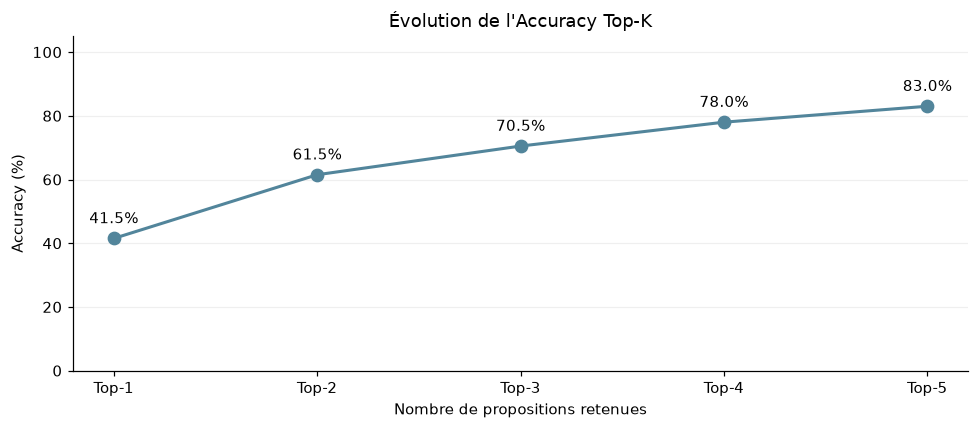

,Top-K,Nb correctes,Accuracy
0,1,83,41.5%
1,2,123,61.5%
2,3,141,70.5%
3,4,156,78.0%
4,5,166,83.0%


In [31]:
import json

# Recherche du rang de la classe attendue
def trouver_rang(row):
    predictions = json.loads(row["top5_predictions"])

    for rang, prediction in enumerate(predictions, start=1):
        if prediction["classe"] == row["label_reel"]:
            return rang

    return np.nan

pred["rang_correct"] = pred.apply(trouver_rang, axis=1)

# Calcul des Accuracy Top-K
accuracy_k = pd.DataFrame({
    "Top-K": range(1, 6),
    "Nb correctes": [
        (pred["rang_correct"] <= k).sum()
        for k in range(1, 6)
    ]
})

accuracy_k["Accuracy"] = accuracy_k["Nb correctes"] / len(pred)

# Visualisation
fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    accuracy_k["Top-K"],
    accuracy_k["Accuracy"] * 100,
    marker="o",
    markersize=8,
    linewidth=2,
    color="#52859b"
)

for k, score in zip(
    accuracy_k["Top-K"],
    accuracy_k["Accuracy"]
):
    ax.annotate(
        f"{score:.1%}",
        (k, score * 100),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

ax.set(
    xticks=range(1, 6),
    xticklabels=[f"Top-{k}" for k in range(1, 6)],
    ylim=(0, 105),
    ylabel="Accuracy (%)",
    xlabel="Nombre de propositions retenues",
    title="Évolution de l'Accuracy Top-K"
)

ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

display(accuracy_k.style.format({"Accuracy": "{:.1%}"}))

**Observation :** L'ajout d'une deuxième proposition permet de passer de 41,5 % à 61,5 % de classifications correctes, soit un gain de 20 points.
Les gains deviennent ensuite progressivement moins importants.
Même si la deuxième proposition apporte le gain le plus important, les propositions suivantes continuent d'améliorer sensiblement les résultats. Il reste donc pertinent de conserver les cinq prédictions dans une logique d'assistance à la classification.

Ces résultats soulèvent toutefois une nouvelle question : toutes les régions anatomiques bénéficient-elles de la même manière de l'augmentation du nombre de propositions ? Certaines classes pourraient être rapidement identifiées, tandis que d'autres nécessiteraient davantage de propositions.

## 7. Questionner la granularité anatomique

Les confusions entre régions du rachis motivent une expérience exploratoire : regrouper les classes cervicale, dorsale, lombaire et générique `SPINE` dans une famille `RACHIS`. Les autres classes restent inchangées. Les annotations et les prédictions existantes sont projetées sur cette taxonomie simplifiée afin d'estimer l'effet d'une tâche moins fine.

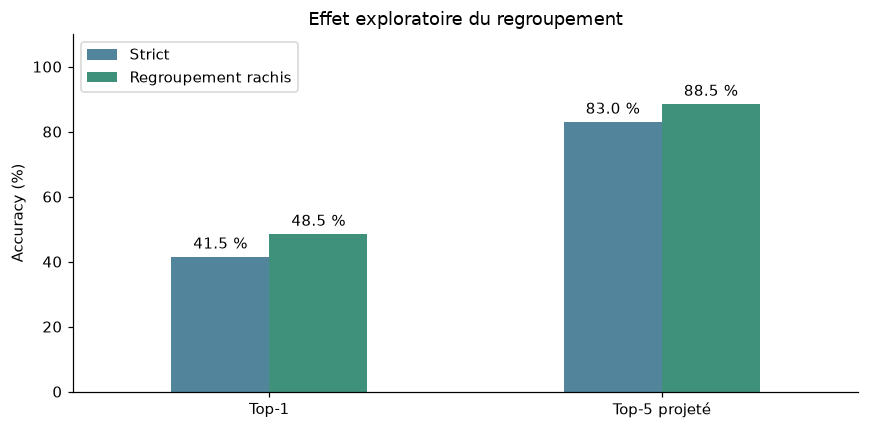

Erreurs Top-1 reclassées comme correctes : 14


label_predit,DORSAL_SPINE,LUMBAR_SPINE,SPINE
label_reel,,,
CERVICAL_SPINE,0,1,0
DORSAL_SPINE,0,11,0
LUMBAR_SPINE,1,0,1


In [17]:
GROUPES = {c: "RACHIS" for c in ["CERVICAL_SPINE", "DORSAL_SPINE", "LUMBAR_SPINE", "SPINE"]}
def famille(c):
    return GROUPES.get(c,c)
reel = pred.label_reel.map(famille)
proj_top1 = pred.label_predit.map(famille)
proj_top5 = pred.top5.map(lambda cs: list(dict.fromkeys(famille(c) for c in cs)))
correct_groupe = reel.eq(proj_top1)
dans_groupe = pd.Series([r in cs for r,cs in zip(reel,proj_top5)], index=pred.index)
granularite = pd.DataFrame({"Strict":[pred.correct.mean(),pred.dans_top5.mean()], "Regroupement rachis":[correct_groupe.mean(),dans_groupe.mean()]},index=["Top-1","Top-5 projeté"])
ax = (100*granularite).plot.bar(figsize=(8,4),color=["#52859b","#40917b"],rot=0)
ax.set(ylim=(0,110),ylabel="Accuracy (%)",title="Effet exploratoire du regroupement")
for c in ax.containers: ax.bar_label(c,fmt="%.1f %%",padding=3)
plt.tight_layout(); plt.show()
print("Erreurs Top-1 reclassées comme correctes :", int((~pred.correct & correct_groupe).sum()))
display(pd.crosstab(pred.loc[~pred.correct & correct_groupe,"label_reel"], pred.loc[~pred.correct & correct_groupe,"label_predit"]))

Le gain éventuel reflète une tâche moins fine, pas une amélioration du modèle. Le Top-5 projeté contient au plus cinq familles distinctes ; les probabilités des 33 classes ne sont pas disponibles pour recalculer un véritable classement par famille. Cette exploration ne valide aucune nouvelle taxonomie métier.

## Retenir les métriques du protocole d'évaluation

Les observations précédentes permettent de justifier les indicateurs à conserver pour les futures expérimentations, sans modifier la définition stricte d'une prédiction correcte.

| Métrique | Définition | Justification issue du diagnostic |
|---|---|---|
| Accuracy Top-1 | Première prédiction correcte | Indispensable pour mesurer la catégorisation automatique. |
| Accuracy Top-5 | Classe attendue parmi cinq propositions | Complément pertinent pour l'assistance, au vu des 83 images récupérées aux rangs 2–5. |
| Précision | TP / (TP + FP) | Identifier les classes générant des faux positifs. |
| Rappel | TP / (TP + FN) | Détecter les régions manquées, comme le rachis cervical. |
| F1-score | Moyenne harmonique précision/rappel | Synthétiser les performances par classe et comparer les configurations. |

Les moyennes macro accordent le même poids aux dix classes évaluées. Les prédictions hors benchmark restent des erreurs si elles diffèrent de l'annotation. La matrice de confusion et les scores individuels sont conservés pour le diagnostic. Le regroupement anatomique reste exploratoire et ne remplace pas les métriques strictes.

## 9. Examiner le prétraitement initial

La diversité des formats observée au départ soulève une autre hypothèse : le Center Crop pourrait supprimer des repères anatomiques utiles. Trois transformations sont visualisées sur les mêmes images : recadrage central, Resize direct et Padding. Il s'agit de comparer l'information visible, avant de mesurer leurs effets sur la classification.

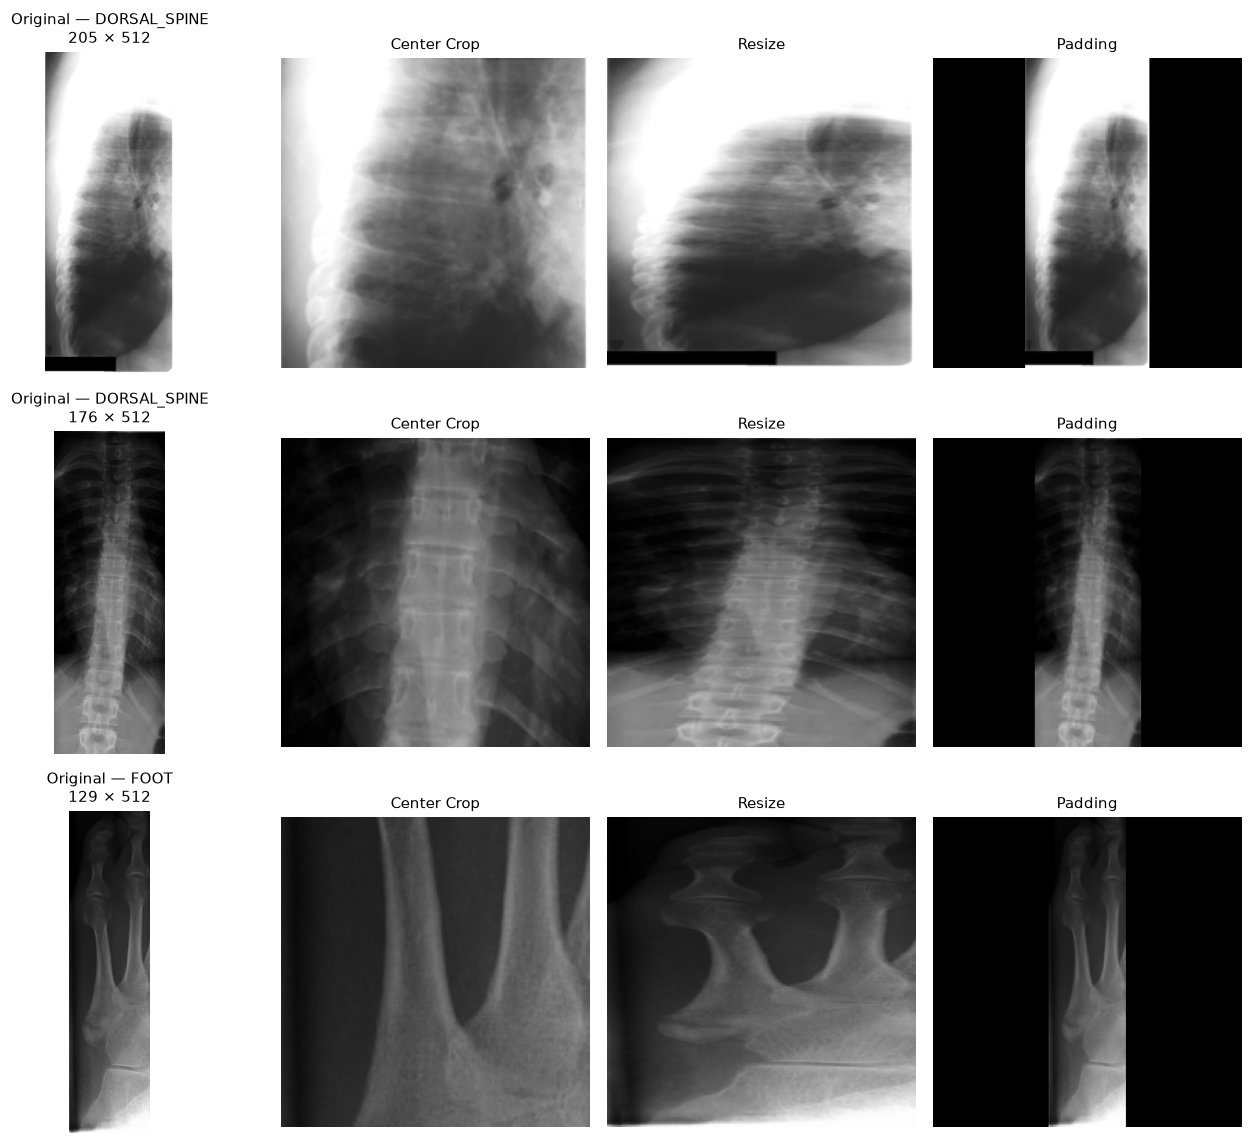

In [18]:
crop = transforms.Compose([transforms.Resize(224), transforms.CenterCrop(224)])
resize = transforms.Resize((224,224))
def padding(im):
    return ImageOps.pad(im,(224,224),method=Image.Resampling.BILINEAR,color=(0,0,0),centering=(.5,.5))
# Deux erreurs de rachis et une image au format particulièrement allongé.
ratio = dimensions.max(axis=1)/dimensions.min(axis=1)
noms_images = list(dict.fromkeys(choix.filename.head(2).tolist()+[labels.loc[ratio.idxmax(),"filename"]]))
fig, axes = plt.subplots(len(noms_images),4,figsize=(12,3.5*len(noms_images)),squeeze=False)
for i,nom in enumerate(noms_images):
    im = lire_image(nom)
    row = pred.loc[pred.filename.eq(nom)].iloc[0]
    for j,(titre,img) in enumerate(zip(["Original","Center Crop","Resize","Padding"],[im,crop(im),resize(im),padding(im)])):
        axes[i,j].imshow(img); axes[i,j].axis("off")
        axes[i,j].set_title(titre if j else f"Original — {row.label_reel}\n{im.width} × {im.height}",fontsize=10)
plt.tight_layout(); plt.show()

**Interprétation :** le Center Crop peut supprimer les bords de l'image ; le Resize conserve le champ complet mais déforme les proportions ; le Padding conserve les proportions au prix d'une surface utile parfois réduite. Ces différences justifient un test contrôlé des trois méthodes à poids et dataset identiques. La visualisation seule ne permet pas de désigner la meilleure méthode.

## Des observations aux expérimentations

| Observation | Hypothèse ou question | Action envisagée |
|---|---|---|
| Écart Top-1 / Top-5 | Difficulté à sélectionner la catégorie exacte | Conserver les deux indicateurs |
| Confusions anatomiques proches | Granularité ou conventions d'annotation | Explorer une taxonomie regroupée |
| Recadrage des images allongées | Perte de contexte | Comparer Center Crop, Resize et Padding |
| Scores élevés possibles sur des erreurs | Score non calibré | Étudier un seuil sur un jeu indépendant |

L'évaluation automatisée (`evaluation/evaluer_modele.py`) et MLflow prennent ensuite le relais pour exécuter, tracer et comparer les tests. Le notebook explique pourquoi ces expérimentations ont été retenues.